# Systematics Correction of *Kepler*/K2 and TESS Light Curves with `k2sc` v2 and Lightkurve

`k2sc` (**v2.0.0**) models space-photometry systematics and intrinsic stellar variability simultaneously as the sum of two Gaussian Processes (GPs) powered by `jax`, `tinygp`, and `equinox`:

$$f(t, x, y) = f_{\mathrm{time}}(t) + f_{\mathrm{pos}}(x, y; t) + \epsilon,$$

where $f_{\mathrm{time}}(t)$ captures smooth or rotational stellar variability and $f_{\mathrm{pos}}(x, y; t)$ captures piecewise-segmented 2D detector pointing drift across roll-angle reversals or sector downlink gaps. With exact JAX reverse-mode automatic differentiation and multi-start bounded `L-BFGS-B` optimization, detrending a full K2 campaign or TESS sector takes **~1–3 seconds on CPU** with zero C++ compilation.

This tutorial demonstrates four idiomatic workflows:
1. **K2 Campaign Detrending** with `K2SCCorrector` (`lightkurve` v2+ API).
2. **Planetary Transit Masking & Diagnostics** (`transit_mask`, `remove_time_trend`, `diagnose()`, and `diagnose_xy()`).
3. **TESS Sector Detrending** (`TessLightCurve` automatic centroid fallback and perigee downlink-gap splitting).
4. **Standalone Functional & Array Interface** (`k2sc.detrend`).

In [1]:
import time as time_mod
from pathlib import Path

import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np

import k2sc
from k2sc import K2SCCorrector

print(f"k2sc version: {k2sc.__version__} | lightkurve version: {lk.__version__}")

k2sc version: 2.0.0 | lightkurve version: 2.6.0


## 1. Detrending a Real K2 Light Curve with `K2SCCorrector`

`K2SCCorrector` subclasses `lightkurve.correctors.Corrector`. It automatically unwraps Astropy `Time`, `Quantity`, and `MaskedNDArray` columns, shifts internal GP timestamps relative to a reference epoch in 64-bit floating-point precision, detects strong rotational periodicity via Lomb–Scargle screening to select between `BasicKernelEP` and `QuasiPeriodicKernel`, and preserves full light curve length and physical flux units.

Below we load EPIC 211436265 (a spotted K2 Campaign 5 star with a ~3.32 d rotation period) from the bundled local FITS test archive so this notebook runs 100% offline in a few seconds; when working online with MAST, you can fetch any target in one line with `lk.search_lightcurve(...).download()`.

In [2]:
# Online MAST query equivalent:
# lc = lk.search_lightcurve("EPIC 211436265", mission="K2", campaign=5).download()

fits_candidates = [
    Path("tests/data_op/ktwo211436265-c05_llc.fits"),
    Path("../tests/data_op/ktwo211436265-c05_llc.fits"),
    Path("../../tests/data_op/ktwo211436265-c05_llc.fits"),
]
fits_path = next(p for p in fits_candidates if p.exists())
lc = lk.read(str(fits_path))

t_start = time_mod.perf_counter()
corr = K2SCCorrector(lc)
clc = corr.correct(
    optimizer="auto",
    tr_nrandom=160,
    tr_nblocks=3,
    tr_bspan=30,
    n_candidates=64,
    maxiter=60,
    seed=0,
)
elapsed = time_mod.perf_counter() - t_start

print(f"Detrended {len(clc)} cadences in {elapsed:.2f} s")
print(f"Selected kernel : {clc.meta['K2SC_KERNEL']} (periodic={corr.result.is_periodic}, P_LS={corr.result.ls_period:.3f} d)")
print(f"6.5-h CDPP (ppm): raw={corr.cdpp_r:.1f} -> position-corrected={corr.cdpp_t:.1f} -> whitened={corr.cdpp_c:.1f}")

Detrended 3450 cadences in 14.24 s
Selected kernel : QuasiPeriodicKernel (periodic=True, P_LS=3.324 d)
6.5-h CDPP (ppm): raw=961.4 -> position-corrected=856.1 -> whitened=110.6


The returned `clc` (`LightCurve`) retains `clc.flux` as the position-corrected flux (preserving astrophysical variability and transits) and attaches the separated GP components and bitmask flags as extra columns:
- `clc["k2sc_tr_position"]`: 2D roll-angle pointing systematics model $T_{\mathrm{pos}}$.
- `clc["k2sc_tr_time"]`: Astrophysical time GP model $T_{\mathrm{time}}$.
- `clc["k2sc_detrended_flux"]`: Fully whitened flux (both $T_{\mathrm{pos}}$ and $T_{\mathrm{time}}$ removed).
- `clc["k2sc_mflags"]`: Quality, outlier, and periodic transit bitmask.

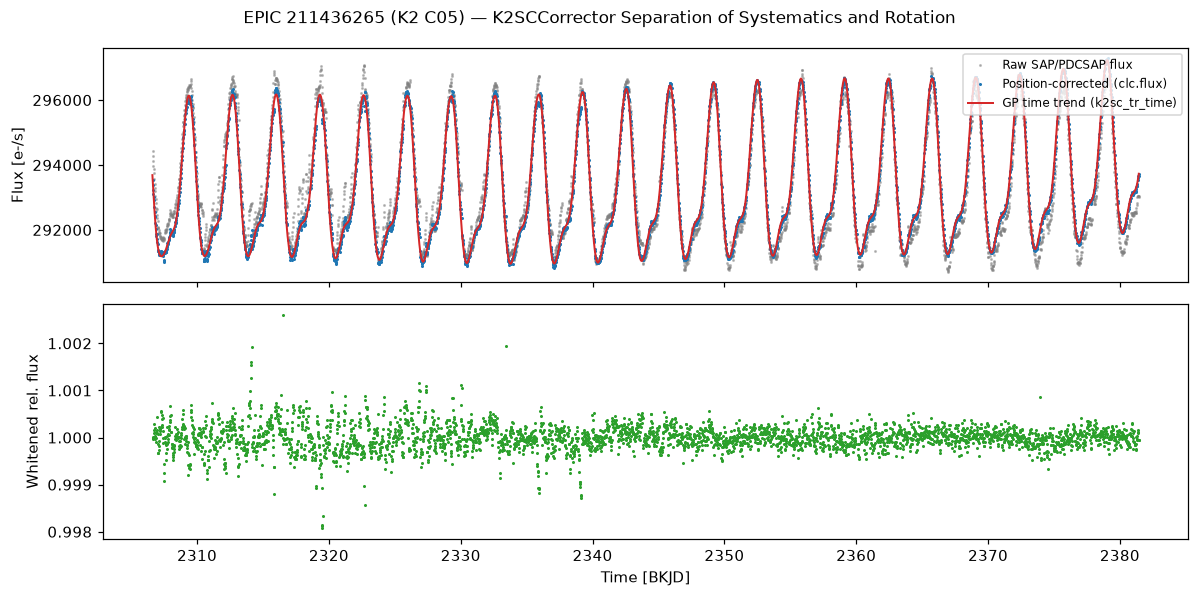

In [3]:
t_bkjd = np.asarray(clc.time.value, dtype=float)
raw_f = np.asarray(lc.flux.value, dtype=float)
pos_corr_f = np.asarray(clc.flux.value, dtype=float)
whitened_f = np.asarray(clc["k2sc_detrended_flux"].value, dtype=float)
tr_time = np.asarray(clc["k2sc_tr_time"].value, dtype=float)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(t_bkjd, raw_f, ".", ms=2, alpha=0.45, color="0.5", label="Raw SAP/PDCSAP flux")
axes[0].plot(t_bkjd, pos_corr_f, ".", ms=2, color="C0", label="Position-corrected (clc.flux)")
axes[0].plot(t_bkjd, tr_time, "-", lw=1.3, color="C3", label="GP time trend (k2sc_tr_time)")
axes[0].set_ylabel("Flux [e-/s]")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t_bkjd, whitened_f / np.nanmedian(whitened_f), ".", ms=2, color="C2")
axes[1].set_ylabel("Whitened rel. flux")
axes[1].set_xlabel("Time [BKJD]")
fig.suptitle("EPIC 211436265 (K2 C05) — K2SCCorrector Separation of Systematics and Rotation", fontsize=11)
fig.tight_layout()

## 2. Transit Masking (`transit_mask`) and Diagnostic Plots

When detrending a planet host with known ephemeris $(t_0, P, T_{\mathrm{dur}})$, passing `transit_mask=(t0, period, duration)` excludes in-transit cadences from outlier sigma-clipping and GP conditioning so deep transits never bias the stellar time kernel or spatial systematics surface. Setting `remove_time_trend=True` then subtracts both $T_{\mathrm{pos}}$ and $T_{\mathrm{time}}$ to yield a flat baseline for transit fitting while keeping the transit depth intact.

In [4]:
# Inject a synthetic 2000 ppm periodic planetary transit into the K2 light curve
t0_inj, per_inj, dur_inj, depth_inj = 2310.2, 5.40, 0.16, 0.0020
phase = ((t_bkjd - t0_inj + 0.5 * per_inj) % per_inj) - 0.5 * per_inj
in_transit = np.abs(phase) < 0.5 * dur_inj

lc_planet = lc.copy()
lc_planet.flux = lc.flux * np.where(in_transit, 1.0 - depth_inj, 1.0)

corr_planet = K2SCCorrector(lc_planet)
clc_flat = corr_planet.correct(
    transit_mask=(t0_inj, per_inj, dur_inj),
    remove_time_trend=True,
    optimizer="auto",
    tr_nrandom=160,
    tr_nblocks=3,
    tr_bspan=30,
    n_candidates=64,
    maxiter=60,
    seed=0,
)

# Measure recovered transit depth on the flattened light curve
rel_flat = np.asarray(clc_flat.flux.value, dtype=float) / np.nanmedian( np.asarray(clc_flat.flux.value, dtype=float) )
finite_in = in_transit & np.isfinite(rel_flat)
finite_out = (~in_transit) & np.isfinite(rel_flat)
recovered_depth_ppm = (np.median(rel_flat[finite_out]) - np.median(rel_flat[finite_in])) * 1e6
print(f"Injected depth: {depth_inj * 1e6:.0f} ppm | Recovered depth after GP whitening: {recovered_depth_ppm:.0f} ppm")

Injected depth: 2000 ppm | Recovered depth after GP whitening: 1998 ppm


`K2SCCorrector` provides two built-in visual diagnostics:
- `corr.diagnose()`: 3-panel time-series overview (raw flux + shifted GP position model, position-detrended flux + GP time trend, and fully whitened residuals).
- `corr.diagnose_xy()`: 2D detector centroid map coloured by the fitted spatial systematics offset $\Delta F_{\mathrm{pos}}$ (ppm).

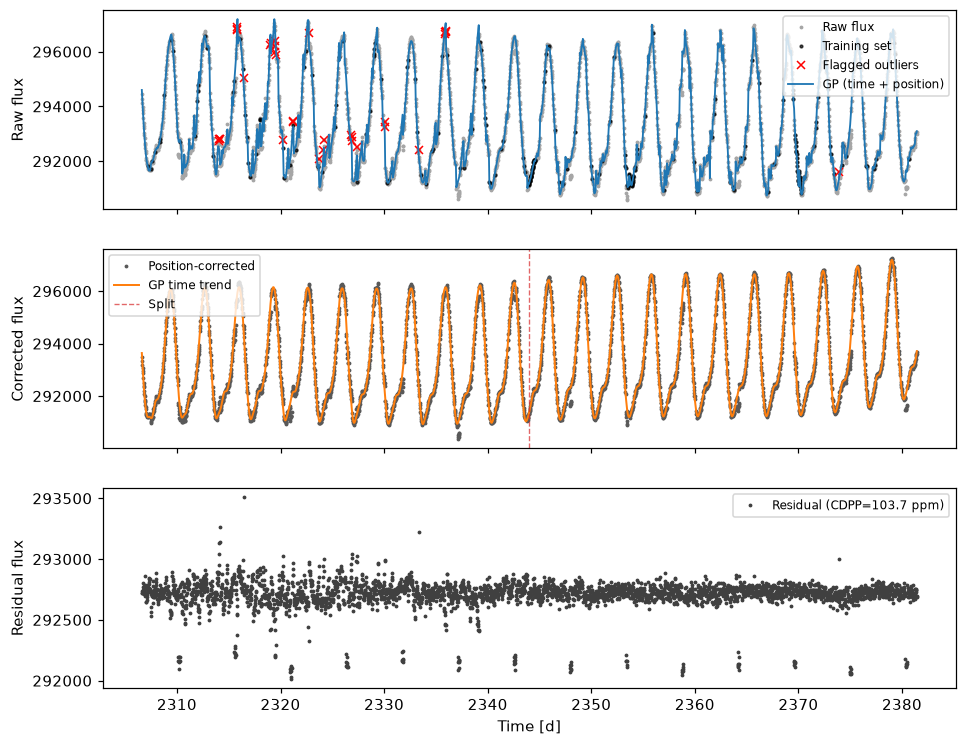

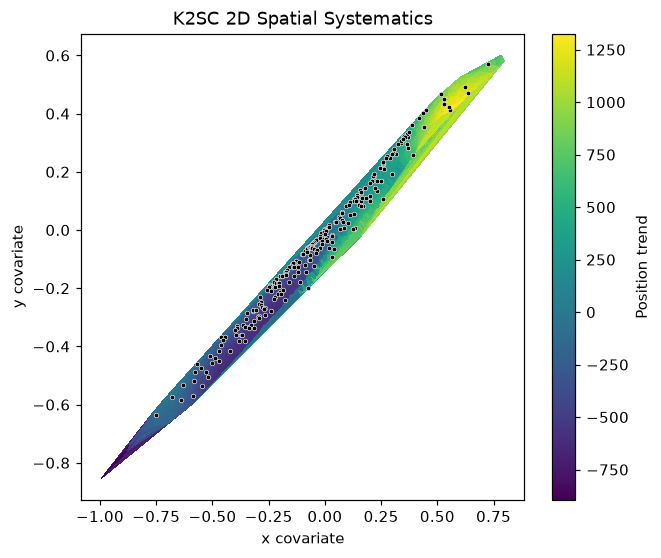

In [5]:
corr_planet.diagnose()
corr_planet.diagnose_xy()

## 3. TESS Sector Detrending (`TessLightCurve`)

`K2SCCorrector` supports TESS SPOC and QLP `TessLightCurve` objects directly:
1. **Automatic Centroid Covariate Fallback:** When `pos_corr1`/`pos_corr2` are absent or NaN, `K2SCCorrector` automatically falls back to median-centred `centroid_col` and `centroid_row` (or `mom_centr1`/`mom_centr2`).
2. **Automatic Perigee Downlink-Gap Splits (`splits="auto"`):** Detects the ~1 d mid-sector data downlink gap ($\Delta t > \max(0.5\,\mathrm{d}, 10\,\mathrm{median}(\Delta t))$) and fits independent spatial systematics realizations on each TESS orbit via `PiecewiseSpatialKernel`.

Covariate source : centroid
Auto-detected gap: splits=[1338.8]
TESS CDPP (ppm)  : raw=74.6 -> position-corrected=47.8 -> whitened=43.6


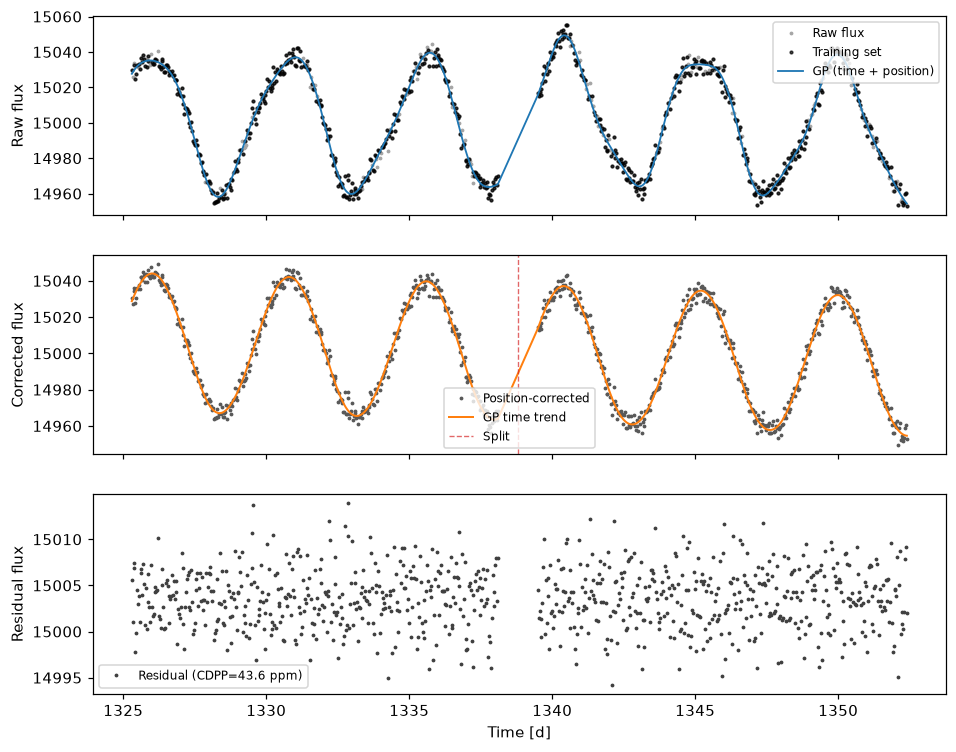

In [6]:
# Online MAST query equivalent for a TESS target:
# tlc = lk.search_lightcurve("TIC 25155310", mission="TESS", sector=1, author="SPOC").download()

rng = np.random.default_rng(42)
t_orb1 = np.linspace(1325.3, 1338.1, 420)
t_orb2 = np.linspace(1339.5, 1352.4, 420)  # 1.4 d perigee downlink gap
t_btjd = np.concatenate([t_orb1, t_orb2])

# Simulated spacecraft jitter + scattered-light attitude ramp per TESS orbit
dx = np.concatenate([0.08 * np.sin(2 * np.pi * t_orb1 / 2.2), 0.10 * np.cos(2 * np.pi * t_orb2 / 1.9)])
dy = np.concatenate([0.06 * (t_orb1 - t_orb1.mean()) / 6.0, -0.09 * (t_orb2 - t_orb2.mean()) / 6.0])
stellar = 0.0025 * np.sin(2 * np.pi * t_btjd / 4.8)
sys_pos = np.concatenate([0.0045 * dx[:420] - 0.0030 * dy[:420], -0.0035 * dx[420:] + 0.0050 * dy[420:]])
flux_e_s = 15000.0 * (1.0 + stellar + sys_pos + rng.normal(0.0, 2.2e-4, t_btjd.size))

tlc = lk.TessLightCurve(
    data={
        "time": t_btjd,
        "flux": flux_e_s,
        "flux_err": np.full_like(flux_e_s, 3.3),
        "centroid_col": 1024.5 + dx,
        "centroid_row": 512.2 + dy,
        "quality": np.zeros(t_btjd.size, dtype=np.int32),
    },
    meta={"MISSION": "TESS", "SECTOR": 1},
)

tcorr = K2SCCorrector(tlc)
ctlc = tcorr.correct(splits="auto", optimizer="auto", seed=0)

print(f"Covariate source : {ctlc.meta['K2SC_COVARIATES']}")
print(f"Auto-detected gap: splits={tcorr.result.splits}")
print(f"TESS CDPP (ppm)  : raw={tcorr.cdpp_r:.1f} -> position-corrected={tcorr.cdpp_t:.1f} -> whitened={tcorr.cdpp_c:.1f}")
tcorr.diagnose()

## 4. Functional & Standalone Array Interface (`k2sc.detrend`)

For custom pipelines, ground/space photometry tables, or array-level batch scripts without `lightkurve`, `k2sc.detrend` accepts 1D NumPy/JAX arrays directly (even when timestamps or covariates contain `NaN` gaps) and returns a `K2SCResult` dataclass.

In [7]:
rng = np.random.default_rng(7)
time_arr = np.linspace(0.0, 36.0, 500)
x_arr = 0.25 * ((time_arr % 0.25) / 0.25 - 0.5)
y_arr = 0.12 * np.sin(2.0 * np.pi * time_arr / 0.25)
flux_arr = 1000.0 * (
    1.0
    + 0.0035 * np.sin(2.0 * np.pi * time_arr / 6.2)
    + 0.0070 * x_arr
    - 0.0040 * y_arr
    + rng.normal(0.0, 2.0e-4, time_arr.size)
)
# Insert a non-finite cadence to verify full-length NaN-safe unpacking
flux_arr[123] = np.nan

res = k2sc.detrend(
    time_arr,
    flux_arr,
    x=x_arr,
    y=y_arr,
    splits=[18.0],
    optimizer="auto",
    seed=0,
)

print(f"Output length preserved: {res.corr_flux.shape[0]} == {time_arr.shape[0]}")
print(f"CDPP raw={res.cdpp_r:.1f} ppm -> pos-corrected={res.cdpp_t:.1f} ppm -> whitened={res.cdpp_c:.1f} ppm")

# k2sc.detrend also dispatches polymorphically on LightCurve instances:
clc_direct = k2sc.detrend(tlc, splits="auto", seed=0)
print(f"Polymorphic LightCurve dispatch returned: {type(clc_direct).__name__}")

Output length preserved: 500 == 500
CDPP raw=35.4 ppm -> pos-corrected=16.8 ppm -> whitened=15.4 ppm
Polymorphic LightCurve dispatch returned: TessLightCurve
